# Density functional theory: the traditional calculation, then an AI surrogate

**What this notebook does.** We take one small molecule (ethanol) and do the job twice.
First with traditional Kohn-Sham DFT, where a program solves the electronic equations for every geometry.
Then with a pretrained machine-learned interatomic potential (MACE-OFF23), which was trained on DFT data and predicts energies and forces directly.

We compare geometry, forces, energy differences and the cost. We also show the limits, because an AI model that agrees with DFT only inside the region it was trained on is not a replacement for DFT.

**Where to run it.** PySCF does not run natively on Windows. Use **Google Colab** (CPU is enough) or WSL/Linux.

**Structure of the notebook**
- *Part 1 (Steps 1 to 10):* the basics on ethanol. Traditional DFT against a pretrained AI potential, with accuracy, cost and limits.
- *Part 2 (Steps 11 to 17):* the model from Part 1 does not know aluminum, so we switch to a model that does and study aluminum nitride (AlN), a semiconductor material: first small clusters (AlN and Al2N2) with DFT and the AI model side by side, then the bulk crystal.

**Two kinds of AI for DFT, only the first is run here**
- *Machine-learned interatomic potentials* (MACE, UMA and others) skip the electronic problem and learn energy and forces from DFT data.
- *Learned exchange-correlation functionals* (Microsoft Skala) keep DFT but replace the hand-designed functional with a neural network.

**Licenses.** PySCF is Apache-2.0. The MACE-OFF23 weights are under the Academic Software License (non-commercial). Check the license of any model before using it in a commercial setting.

## Setup

In [ ]:
# Run once in Colab (remove the leading '#' of the next line), then restart the runtime if asked.
!pip install -q --prefer-binary pyscf pyscf-dispersion ase mace-torch rdkit

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 106.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.1/469.1 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 6.7 MB/s eta 0:00:00


## Settings

In [ ]:
%matplotlib inline
from pathlib import Path

OUT_DIR = Path("outputs/dft_vs_ai")

SMILES = "CCO"             # ethanol
DFT_XC = "b3lyp"           # exchange-correlation functional
DFT_DISP = "d3bj"          # dispersion correction
DFT_BASIS = "def2-svp"     # basis set
MACE_MODEL = "small"       # small, medium or large (MACE-OFF23)
MACE_DEVICE = "auto"       # auto uses the GPU if there is one (Colab: Runtime > Change runtime type > GPU)
MACE_DTYPE = "float64"     # float64 is safest for relaxation; float32 is faster on the GPU
FMAX = 0.02                # geometry optimization stops when all forces are below this (eV/A)

N_DISTORTED = 20           # randomly distorted geometries for the force comparison
RATTLE_A = 0.05            # size of the random displacement (A)
SEED = 0

CHAIN_DFT = [1, 2, 3, 4, 5, 6]        # alcohols with this many carbons, timed with DFT and MACE
CHAIN_MACE_ONLY = [10, 20, 40, 80]    # larger ones, timed with MACE only
N_TIMING_REPEATS = 5

TORSION_STEP_DEG = 30      # rotate the O-H group around the C-O bond
MD_STEPS = 2000
MD_DT_FS = 0.5
MD_TEMP_K = 300

# Part 2: aluminum nitride
MP_MODEL = "medium"        # MACE-MP-0 size (small, medium, large)
CLUSTER_SPINS = [0, 2, 4]  # 2S: singlet, triplet, quintet
CLUSTER_FMAX = 0.03        # DFT relaxation threshold for the clusters (eV/A)
MACE_CLUSTER_FMAX = 0.005  # the AI model is cheap, so it is converged more tightly
DFT_FREQUENCIES = True     # vibrational check with DFT (slowest part of Part 2; set False to skip)
LIT_A, LIT_C = 3.112, 4.982   # wurtzite AlN lattice constants from the literature (A)
LIT_A_ZB = 4.38               # zincblende AlN, literature (A), a theoretical value

## Imports and helper functions

In [ ]:
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from ase import Atoms, units
from ase.calculators.calculator import Calculator, all_changes
from ase.optimize import BFGS
from ase.build import minimize_rotation_and_translation
from ase.neighborlist import natural_cutoffs, neighbor_list
from ase.md.langevin import Langevin
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution
from ase.io import write
from ase.build import bulk
from ase.filters import FrechetCellFilter
from ase.vibrations import Vibrations
from rdkit import Chem
from rdkit.Chem import AllChem
from pyscf import gto, dft, lib
import torch

OUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
DEVICE = ("cuda" if torch.cuda.is_available() else "cpu") if MACE_DEVICE == "auto" else MACE_DEVICE
print("DFT (PySCF) runs on the CPU with", lib.num_threads(), "threads")
print("MACE runs on:", DEVICE, "-", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU found")


class PySCFCalculator(Calculator):
    """Kohn-Sham DFT (closed shell, density fitted) as an ASE calculator: energy in eV, forces in eV/A."""
    implemented_properties = ["energy", "forces"]

    def __init__(self, xc, basis, disp=None, spin=0, unrestricted=False, **kw):
        super().__init__(**kw)
        self.xc, self.basis, self.disp = xc, basis, disp
        self.spin, self.unrestricted = spin, unrestricted      # spin = 2S (number of unpaired electrons)
        self.s2 = None
        self._dm = None
        self.n_calls = 0

    def calculate(self, atoms=None, properties=("energy",), system_changes=all_changes):
        super().calculate(atoms, properties, system_changes)
        spec = [(s, tuple(p)) for s, p in zip(atoms.get_chemical_symbols(), atoms.get_positions())]
        mol = gto.M(atom=spec, basis=self.basis, spin=self.spin, verbose=0)
        mf = (dft.UKS(mol) if (self.unrestricted or self.spin) else dft.RKS(mol)).density_fit()
        mf.xc = self.xc
        mf.grids.level = 3
        mf.conv_tol = 1e-9
        if self.disp:
            mf.disp = self.disp
        e = mf.kernel(dm0=self._dm)
        if not mf.converged:                       # retry from a fresh guess with a level shift
            mf.level_shift, mf.max_cycle = 0.2, 200
            e = mf.kernel()
        if not mf.converged:                       # last resort: second-order solver
            mf = mf.newton()
            e = mf.kernel()
        if not mf.converged:
            raise RuntimeError("SCF did not converge")
        self._dm = mf.make_rdm1()
        self.s2 = float(mf.spin_square()[0]) if (self.unrestricted or self.spin) else 0.0
        g = mf.nuc_grad_method().kernel()          # Hartree / Bohr
        self.results["energy"] = e * units.Hartree
        self.results["forces"] = -g * units.Hartree / units.Bohr
        self.n_calls += 1


def smiles_to_atoms(smiles, seed=0):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
    cid = AllChem.EmbedMolecule(mol, randomSeed=seed, useRandomCoords=True, maxAttempts=50)
    if cid < 0:
        raise RuntimeError("could not build 3D coordinates for " + smiles)
    AllChem.MMFFOptimizeMolecule(mol, maxIters=5000)
    conf = mol.GetConformer()
    pos = np.array([list(conf.GetAtomPosition(i)) for i in range(mol.GetNumAtoms())])
    return Atoms([a.GetSymbol() for a in mol.GetAtoms()], positions=pos)


def relax(atoms, calc, fmax=FMAX, steps=200):
    a = atoms.copy(); a.calc = calc
    t = time.perf_counter()
    opt = BFGS(a, logfile=None)
    opt.run(fmax=fmax, steps=steps)
    return a, opt.get_number_of_steps(), time.perf_counter() - t


def time_forces(atoms, calc, repeats=N_TIMING_REPEATS):
    a = atoms.copy(); a.calc = calc
    a.get_forces()                                   # warm-up call, not timed
    ts = []
    for k in range(repeats):
        b = atoms.copy(); b.rattle(0.01, seed=k); b.calc = calc
        t = time.perf_counter(); b.get_forces(); ts.append(time.perf_counter() - t)
    return float(np.median(ts))


def draw_molecule(ax, atoms, color_by_element=True, alpha=1.0, label=None, color=None, size=1.0):
    col = {"H": "#bbbbbb", "C": "#444444", "O": "#d62728", "N": "#1f77b4", "Al": "#e8a33d"}
    i, j = neighbor_list("ij", atoms, natural_cutoffs(atoms, mult=1.1))
    P = atoms.get_positions()
    for a, b in zip(i, j):
        if a < b:
            ax.plot(*zip(P[a], P[b]), color=color or "#777777", lw=2, alpha=alpha)
    ax.scatter(*P.T, s=[size * (60 if s != "H" else 25) for s in atoms.get_chemical_symbols()],
               c=color if color else [col.get(s, "#2ca02c") for s in atoms.get_chemical_symbols()],
               alpha=alpha, label=label, depthshade=False)
    ax.set_axis_off()


def bond_table(atoms, mult=1.1):
    i, j = neighbor_list("ij", atoms, natural_cutoffs(atoms, mult=mult))
    sym = atoms.get_chemical_symbols()
    rows = []
    for a, b in zip(i, j):
        if a < b:
            rows.append((a, b, "-".join(sorted([sym[a], sym[b]])), atoms.get_distance(a, b)))
    return pd.DataFrame(rows, columns=["i", "j", "type", "length_A"])

DFT (PySCF) runs on the CPU with 2 threads
MACE runs on: cuda - Tesla T4


## Step 1: The molecule

We start from a quick force-field geometry (RDKit MMFF). It is a reasonable guess but not a quantum mechanical answer.
Both methods will start from this same structure.

C2H6O with 9 atoms
electrons: 26


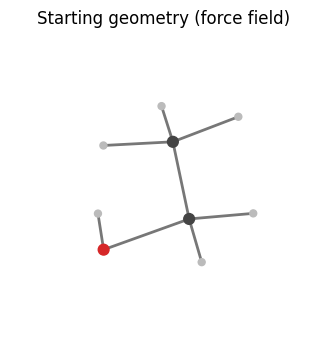

In [ ]:
start = smiles_to_atoms(SMILES, SEED)
print(start.get_chemical_formula(), "with", len(start), "atoms")
print("electrons:", int(sum(start.get_atomic_numbers())))

fig = plt.figure(figsize=(4.5, 4)); ax = fig.add_subplot(projection="3d")
draw_molecule(ax, start); ax.set_title("Starting geometry (force field)")
plt.savefig(OUT_DIR / "dft_molecule.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 2: Traditional DFT

For every geometry the program builds the electron density self-consistently (the Kohn-Sham equations), then evaluates the energy and the forces on the atoms.
We use the functional, dispersion correction and basis set from the settings. We relax the geometry until the forces are small, and time everything.

In [ ]:
dft_calc = PySCFCalculator(DFT_XC, DFT_BASIS, DFT_DISP)
t0 = time.perf_counter(); e0 = dft_calc.get_potential_energy(start); t_single = time.perf_counter() - t0
print(f"single point on the starting geometry: {e0:.3f} eV in {t_single:.1f} s")

dft_opt, dft_steps, dft_opt_time = relax(start, dft_calc)
print(f"DFT relaxation: {dft_steps} steps, {dft_opt_time:.0f} s, final energy {dft_opt.get_potential_energy():.3f} eV")
print(f"energy lowered by {e0 - dft_opt.get_potential_energy():.3f} eV during relaxation")

single point on the starting geometry: -4215.847 eV in 13.4 s
DFT relaxation: 18 steps, 106 s, final energy -4215.885 eV
energy lowered by 0.037 eV during relaxation


## Step 3: The AI model on the same task

MACE-OFF23 is an equivariant graph neural network trained on about a million organic-molecule structures computed with a high-level DFT method (SPICE dataset, wB97M-D3(BJ)).
It takes atomic positions and element types and returns energy and forces. No electronic structure is solved.

In [ ]:
from mace.calculators import mace_off
mace_calc = mace_off(model=MACE_MODEL, device=DEVICE, default_dtype=MACE_DTYPE)

warm = start.copy(); warm.calc = mace_calc; warm.get_forces()      # first call on a GPU includes start-up cost, so it is not timed
mace_opt, mace_steps, mace_opt_time = relax(start, mace_calc)
print(f"MACE relaxation: {mace_steps} steps, {mace_opt_time:.1f} s")
print(f"DFT relaxation took {dft_opt_time / max(mace_opt_time, 1e-9):.0f} times longer")

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
The model is distributed under the Academic Software License (ASL) license, see https://github.com/gabor1/ASL 
 To use the model you accept the terms of the license.
ASL is based on the Gnu Public License, but does not permit commercial use
Downloading: 100.0% (7.0 MB / 7.0 MB)
Cached MACE model to /root/.cache/mace/MACE-OFF23_small.model
Using MACE-OFF23 MODEL for MACECalculator with /root/.cache/mace/MACE-OFF23_small.model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
MACE relaxation: 16 steps, 1.7 s
DFT relaxation took 62 times longer


## Step 4: Do they agree on the structure?

We superimpose the two relaxed structures and compare bond lengths. Both started from the same guess and each followed its own forces.

RMSD between relaxed structures: 0.011 A
      length_A_dft  length_A_mace  diff_A
type                                     
C-C          1.523          1.517  -0.006
C-H          1.104          1.090  -0.014
C-O          1.412          1.423   0.010
H-O          0.966          0.959  -0.008
largest single bond difference: 0.017 A


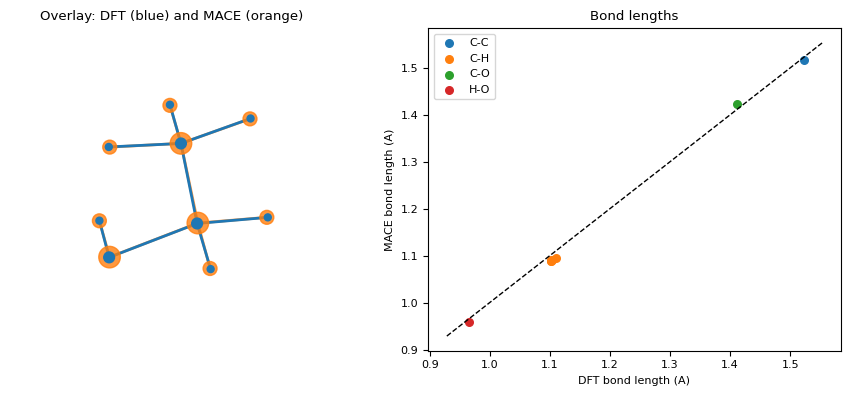

In [ ]:
mace_aligned = mace_opt.copy()
minimize_rotation_and_translation(dft_opt, mace_aligned)
rmsd = float(np.sqrt(((dft_opt.get_positions() - mace_aligned.get_positions()) ** 2).sum(1).mean()))
print(f"RMSD between relaxed structures: {rmsd:.3f} A")

bd, bm = bond_table(dft_opt), bond_table(mace_opt)
bonds = bd.merge(bm, on=["i", "j", "type"], suffixes=("_dft", "_mace"))
bonds["diff_A"] = bonds.length_A_mace - bonds.length_A_dft
print(bonds.groupby("type")[["length_A_dft", "length_A_mace", "diff_A"]].mean().round(3))
print(f"largest single bond difference: {bonds.diff_A.abs().max():.3f} A")

fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
draw_molecule(ax, mace_aligned, color="#ff7f0e", alpha=0.8, size=4.0)
draw_molecule(ax, dft_opt, color="#1f77b4", alpha=1.0, size=1.0)
ax.set_title("Overlay: DFT (blue) and MACE (orange)")
ax2 = fig.add_subplot(1, 2, 2)
for t, g in bonds.groupby("type"):
    ax2.scatter(g.length_A_dft, g.length_A_mace, label=t, s=30)
lo, hi = bonds[["length_A_dft", "length_A_mace"]].values.min() - .03, bonds[["length_A_dft", "length_A_mace"]].values.max() + .03
ax2.plot([lo, hi], [lo, hi], "k--", lw=1)
ax2.set_xlabel("DFT bond length (A)"); ax2.set_ylabel("MACE bond length (A)"); ax2.legend(); ax2.set_title("Bond lengths")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_structure.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 5: Do they agree on forces and energy differences?

A relaxed structure is only one point. For molecular dynamics the model must be right for many distorted geometries.
We create random distortions of the DFT structure, compute DFT and MACE on each, and compare.

Absolute energies are not comparable because the two methods use different functionals and different energy zero points.
What matters physically is the energy *difference* between geometries, so we compare energies relative to the average.

20 distorted geometries, displacement sigma 0.05 A
forces:  MAE 266 meV/A, RMSE 336 meV/A, R2 0.977
relative energies: RMSE 82 meV, R2 0.937
typical DFT force magnitude (RMS): 2205 meV/A


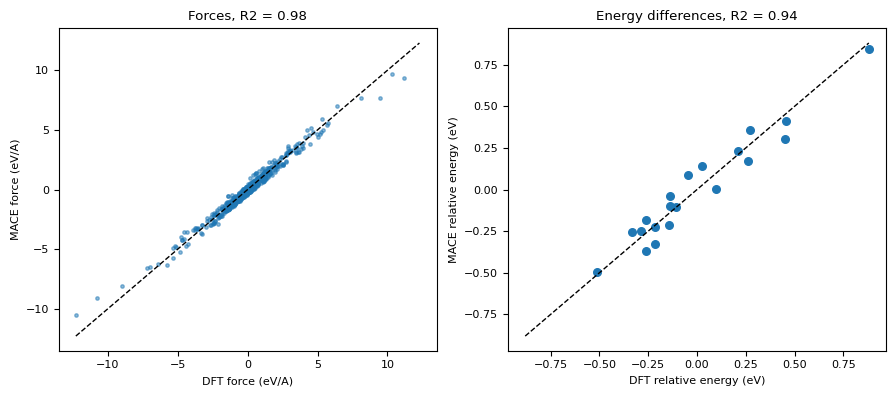

In [ ]:
frames, E_d, E_m, F_d, F_m = [], [], [], [], []
t_dft_frames = []
for k in range(N_DISTORTED):
    a = dft_opt.copy(); a.rattle(RATTLE_A, seed=int(rng.integers(1e9)))
    t = time.perf_counter()
    a.calc = dft_calc; e_d = a.get_potential_energy(); f_d = a.get_forces()
    t_dft_frames.append(time.perf_counter() - t)
    b = a.copy(); b.calc = mace_calc; e_m = b.get_potential_energy(); f_m = b.get_forces()
    frames.append(a); E_d.append(e_d); E_m.append(e_m); F_d.append(f_d); F_m.append(f_m)

E_d, E_m = np.array(E_d), np.array(E_m)
rel_d, rel_m = E_d - E_d.mean(), E_m - E_m.mean()
fd, fm = np.concatenate(F_d).ravel(), np.concatenate(F_m).ravel()

force_mae = np.abs(fd - fm).mean() * 1000
force_rmse = np.sqrt(((fd - fm) ** 2).mean()) * 1000
force_r2 = 1 - ((fd - fm) ** 2).sum() / ((fd - fd.mean()) ** 2).sum()
energy_rmse = np.sqrt(((rel_d - rel_m) ** 2).mean()) * 1000
energy_r2 = 1 - ((rel_d - rel_m) ** 2).sum() / (rel_d ** 2).sum()
print(f"{N_DISTORTED} distorted geometries, displacement sigma {RATTLE_A} A")
print(f"forces:  MAE {force_mae:.0f} meV/A, RMSE {force_rmse:.0f} meV/A, R2 {force_r2:.3f}")
print(f"relative energies: RMSE {energy_rmse:.0f} meV, R2 {energy_r2:.3f}")
print(f"typical DFT force magnitude (RMS): {np.sqrt((fd**2).mean())*1000:.0f} meV/A")

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].scatter(fd, fm, s=6, alpha=.5); l = max(abs(fd).max(), abs(fm).max()); ax[0].plot([-l, l], [-l, l], "k--", lw=1)
ax[0].set_xlabel("DFT force (eV/A)"); ax[0].set_ylabel("MACE force (eV/A)"); ax[0].set_title(f"Forces, R2 = {force_r2:.2f}")
ax[1].scatter(rel_d, rel_m, s=30); l = max(abs(rel_d).max(), abs(rel_m).max()); ax[1].plot([-l, l], [-l, l], "k--", lw=1)
ax[1].set_xlabel("DFT relative energy (eV)"); ax[1].set_ylabel("MACE relative energy (eV)"); ax[1].set_title(f"Energy differences, R2 = {energy_r2:.2f}")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_forces.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 6: A physical test, rotating the O-H group

The hydroxyl hydrogen of ethanol rotates around the C-O bond and passes through energy minima and barriers.
This torsion is a classic test: a useful model must reproduce the shape of the curve, not only the minimum.
We rotate only the hydrogen, keep everything else fixed, and compute both methods at each angle.

barrier height  DFT 103 meV   MACE 85 meV
curve RMSE 15.5 meV


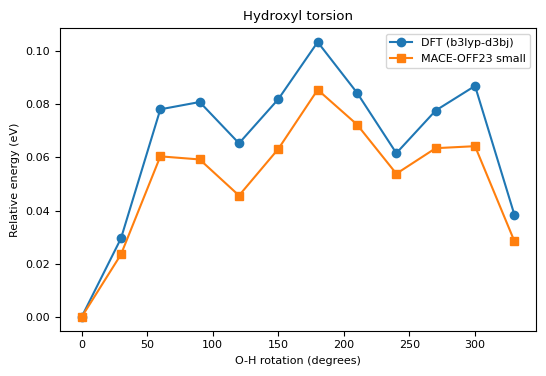

In [ ]:
sym = dft_opt.get_chemical_symbols()
iO = sym.index("O")
nb_ = neighbor_list("ij", dft_opt, natural_cutoffs(dft_opt, mult=1.1))
nbrs = lambda x: [b for a, b in zip(*nb_) if a == x]
iH = [k for k in nbrs(iO) if sym[k] == "H"][0]
iC1 = [k for k in nbrs(iO) if sym[k] == "C"][0]
iC2 = [k for k in nbrs(iC1) if sym[k] == "C"][0]
angle0 = dft_opt.get_dihedral(iC2, iC1, iO, iH)
mask = [k == iH for k in range(len(dft_opt))]

angles = np.arange(0, 360, TORSION_STEP_DEG)
tor_d, tor_m = [], []
for ang in angles:
    a = dft_opt.copy(); a.set_dihedral(iC2, iC1, iO, iH, angle0 + ang, mask=mask)
    tor_d.append(dft_calc.get_potential_energy(a)); tor_m.append(mace_calc.get_potential_energy(a))
tor_d, tor_m = np.array(tor_d), np.array(tor_m)
tor_d -= tor_d.min(); tor_m -= tor_m.min()
print(f"barrier height  DFT {tor_d.max()*1000:.0f} meV   MACE {tor_m.max()*1000:.0f} meV")
print(f"curve RMSE {np.sqrt(((tor_d-tor_m)**2).mean())*1000:.1f} meV")

plt.figure(figsize=(5.5, 3.8))
plt.plot(angles, tor_d, "o-", label=f"DFT ({DFT_XC}-{DFT_DISP})"); plt.plot(angles, tor_m, "s-", label=f"MACE-OFF23 {MACE_MODEL}")
plt.xlabel("O-H rotation (degrees)"); plt.ylabel("Relative energy (eV)"); plt.legend(); plt.title("Hydroxyl torsion")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_torsion.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 7: The cost. Why bother with AI at all?

A note on the comparison: PySCF runs on the CPU, while MACE runs on the GPU when one is available, which is how neural network potentials are normally used. Part of the speed difference therefore comes from the hardware, and part from the method itself. The settings let you set `MACE_DEVICE = "cpu"` to see the method-only difference.

If DFT already gives the answer, a surrogate is only useful if it saves a lot of time for something we actually need.
Where it matters is the number of force evaluations: molecular dynamics needs hundreds of thousands to millions of them, screening needs thousands of molecules, and DFT cost grows steeply with the number of atoms.

First we time one energy-and-force evaluation as the molecule grows. Linear alcohols with 1 to 6 carbons are done with both methods, larger ones with MACE only.

C1: 6 atoms  DFT 2.94 s   MACE 0.030 s
C2: 9 atoms  DFT 6.41 s   MACE 0.034 s
C3: 12 atoms  DFT 11.31 s   MACE 0.037 s
C4: 15 atoms  DFT 17.99 s   MACE 0.042 s
C5: 18 atoms  DFT 26.44 s   MACE 0.043 s
C6: 21 atoms  DFT 38.32 s   MACE 0.053 s
C10: 33 atoms  MACE 0.032 s
C20: 63 atoms  MACE 0.046 s
C40: 123 atoms  MACE 0.077 s
C80: 243 atoms  MACE 0.145 s
measured scaling with atom count: DFT ~ N^2.0
MACE: 0.030 s at 6 atoms, 0.145 s at 243 atoms (on a GPU the time is dominated by launch overhead for small systems, so it stays almost flat)


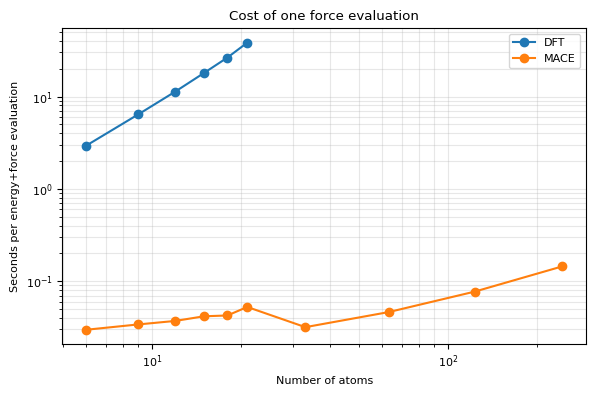

In [ ]:
def alcohol(n): return smiles_to_atoms("C" * n + "O", SEED)

rows = []
for n in CHAIN_DFT:
    a = alcohol(n)
    rows.append(dict(carbons=n, atoms=len(a), method="DFT", seconds=time_forces(a, PySCFCalculator(DFT_XC, DFT_BASIS, DFT_DISP))))
    rows.append(dict(carbons=n, atoms=len(a), method="MACE", seconds=time_forces(a, mace_calc)))
    print(f"C{n}: {len(a)} atoms  DFT {rows[-2]['seconds']:.2f} s   MACE {rows[-1]['seconds']:.3f} s", flush=True)
for n in CHAIN_MACE_ONLY:
    a = alcohol(n)
    rows.append(dict(carbons=n, atoms=len(a), method="MACE", seconds=time_forces(a, mace_calc)))
    print(f"C{n}: {len(a)} atoms  MACE {rows[-1]['seconds']:.3f} s", flush=True)
timing = pd.DataFrame(rows); timing.to_csv(OUT_DIR / "dft_timing.csv", index=False)

td = timing[timing.method == "DFT"]
slope = np.polyfit(np.log(td.atoms), np.log(td.seconds), 1)[0] if len(td) > 1 else float("nan")
tm = timing[timing.method == "MACE"]
print(f"measured scaling with atom count: DFT ~ N^{slope:.1f}")
print(f"MACE: {tm.seconds.min():.3f} s at {int(tm.atoms.min())} atoms, {tm.seconds.max():.3f} s at {int(tm.atoms.max())} atoms "
      f"(on a GPU the time is dominated by launch overhead for small systems, so it stays almost flat)")

plt.figure(figsize=(6, 4))
for m, g in timing.groupby("method"):
    plt.loglog(g.atoms, g.seconds, "o-", label=m)
plt.xlabel("Number of atoms"); plt.ylabel("Seconds per energy+force evaluation"); plt.legend(); plt.grid(alpha=.3, which="both")
plt.title("Cost of one force evaluation")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_cost.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 8: A molecular dynamics run that DFT would struggle to do

Molecular dynamics moves the atoms step by step using the forces: thousands of force evaluations for even half a picosecond.
We run MACE-driven dynamics at the chosen temperature and record how long it takes.
Then we use the DFT time per force evaluation measured above on ethanol to estimate what the same trajectory would cost with DFT, and what a nanosecond would cost.

MACE: 2000 steps (1.00 ps) in 56 s, 35.6 steps/s
DFT for the same trajectory: about 3.6 hours (at 6.4 s per force call)
One nanosecond = 2,000,000 steps: MACE about 15.6 hours, DFT about 0.4 years
mean temperature 305 K, O-H length 0.961 +/- 0.024 A


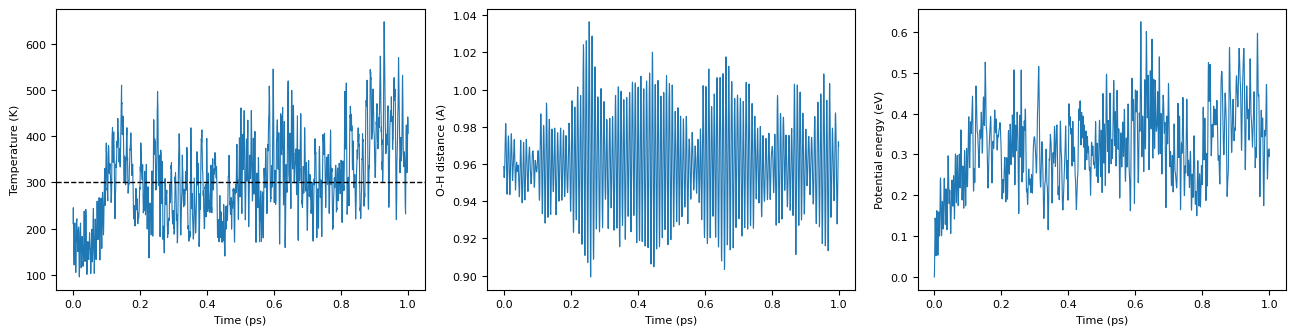

In [ ]:
md_atoms = mace_opt.copy(); md_atoms.calc = mace_calc
MaxwellBoltzmannDistribution(md_atoms, temperature_K=MD_TEMP_K, rng=np.random.default_rng(SEED))
dyn = Langevin(md_atoms, MD_DT_FS * units.fs, temperature_K=MD_TEMP_K, friction=0.01 / units.fs, rng=np.random.default_rng(SEED))
traj, T_log, OH_log, E_log = [], [], [], []
def record():
    T_log.append(md_atoms.get_temperature()); OH_log.append(md_atoms.get_distance(iO, iH)); E_log.append(md_atoms.get_potential_energy())
    if len(T_log) % 10 == 1: traj.append(md_atoms.copy())
dyn.attach(record, interval=1)
t = time.perf_counter(); dyn.run(MD_STEPS); md_time = time.perf_counter() - t
write(OUT_DIR / "dft_md.xyz", traj)

t_dft_force = float(td[td.atoms == len(start)].seconds.iloc[0]) if (td.atoms == len(start)).any() else float(np.mean(t_dft_frames))
sim_ps = MD_STEPS * MD_DT_FS / 1000
dft_equiv = MD_STEPS * t_dft_force
steps_ns = 1e6 / MD_DT_FS
print(f"MACE: {MD_STEPS} steps ({sim_ps:.2f} ps) in {md_time:.0f} s, {MD_STEPS/md_time:.1f} steps/s")
print(f"DFT for the same trajectory: about {dft_equiv/3600:.1f} hours (at {t_dft_force:.1f} s per force call)")
print(f"One nanosecond = {steps_ns:,.0f} steps: MACE about {steps_ns*md_time/MD_STEPS/3600:.1f} hours, DFT about {steps_ns*t_dft_force/86400/365:.1f} years")
print(f"mean temperature {np.mean(T_log):.0f} K, O-H length {np.mean(OH_log):.3f} +/- {np.std(OH_log):.3f} A")

t_ps = np.arange(len(T_log)) * MD_DT_FS / 1000
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(t_ps, T_log, lw=.8); ax[0].axhline(MD_TEMP_K, color="k", ls="--", lw=1); ax[0].set_ylabel("Temperature (K)")
ax[1].plot(t_ps, OH_log, lw=.8); ax[1].set_ylabel("O-H distance (A)")
ax[2].plot(t_ps, np.array(E_log) - np.min(E_log), lw=.8); ax[2].set_ylabel("Potential energy (eV)")
for a in ax: a.set_xlabel("Time (ps)")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_md.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 9: Where the AI model should not be trusted

A surrogate only knows what its training data showed it.
Two quick checks:

1. **Elements outside the training set.** MACE-OFF23 covers ten elements (H, C, N, O, F, P, S, Cl, Br, I). We ask for a molecule containing iron.
2. **Inherited error.** The surrogate cannot be better than the DFT it learned from. Here our DFT is a cheaper functional than the one used for training, so part of the disagreement in the earlier steps is not an AI error at all, it is two different levels of theory.

In [ ]:
try:
    bad = Atoms("FeO", positions=[[0, 0, 0], [0, 0, 1.6]]); bad.calc = mace_calc; bad.get_potential_energy()
    print("unexpectedly returned an energy")
except Exception as e:
    print("Asking MACE-OFF23 about iron fails:", type(e).__name__, "-", str(e)[:120])

Asking MACE-OFF23 about iron fails: ValueError - np.int64(26) is not in list


## Step 10: Summary table

In [ ]:
summary = {
    "molecule": SMILES, "atoms": len(start),
    "dft_level": f"{DFT_XC}-{DFT_DISP}/{DFT_BASIS}", "mace_model": f"MACE-OFF23 {MACE_MODEL}", "mace_device": DEVICE, "mace_dtype": MACE_DTYPE, "dft_device": "cpu",
    "relax_dft_s": round(dft_opt_time, 1), "relax_mace_s": round(mace_opt_time, 2),
    "relax_dft_steps": dft_steps, "relax_mace_steps": mace_steps,
    "structure_rmsd_A": round(rmsd, 3), "max_bond_diff_A": round(float(bonds.diff_A.abs().max()), 3),
    "force_mae_meV_A": round(float(force_mae), 1), "force_r2": round(float(force_r2), 3),
    "rel_energy_rmse_meV": round(float(energy_rmse), 1), "rel_energy_r2": round(float(energy_r2), 3),
    "torsion_barrier_dft_meV": round(float(tor_d.max() * 1000), 1), "torsion_barrier_mace_meV": round(float(tor_m.max() * 1000), 1),
    "dft_s_per_force": round(t_dft_force, 2),
    "mace_s_per_force": round(float(tm[tm.atoms == len(start)].seconds.iloc[0]), 4) if (tm.atoms == len(start)).any() else None,
    "scaling_exponent_dft": round(float(slope), 2),
    "mace_s_smallest": round(float(tm.seconds.iloc[0]), 4), "mace_s_largest": round(float(tm.seconds.iloc[-1]), 4), "mace_largest_atoms": int(tm.atoms.max()),
    "md_steps": MD_STEPS, "md_wall_s": round(md_time, 1),
}
json.dump(summary, open(OUT_DIR / "dft_summary.json", "w"), indent=2)
pd.Series(summary).to_frame("value")

,value
molecule,CCO
atoms,9
dft_level,b3lyp-d3bj/def2-svp
mace_model,MACE-OFF23 small
mace_device,cuda
mace_dtype,float64
dft_device,cpu
relax_dft_s,106.2
relax_mace_s,1.71
relax_dft_steps,18


# Part 2: aluminum nitride

Part 1 ended with a real limitation: MACE-OFF23 does not know aluminum. Aluminum nitride (AlN) is a wide band gap semiconductor, used in power electronics, deep-UV light sources and as a heat-spreading material, so it is exactly the kind of material where this question matters.

Decades ago, first-principles calculations on small AlN clusters, with unrestricted spin and long convergence times, were serious multi-day jobs. Here the DFT part takes seconds to minutes. The question is whether a pretrained AI potential can follow.

We need a model that covers Al and N. We use **MACE-MP-0**, trained on the Materials Project (mostly crystals, PBE-level DFT, 89 elements, MIT license). That also tells us what to expect: it should be strong for the bulk crystal and is a stretch for isolated gas-phase clusters. We test both.

Two things change compared with Part 1:
- **Spin.** Small Al-N clusters can have unpaired electrons. Our Part 1 DFT assumed a closed-shell molecule. Now we use unrestricted DFT and try several spin states.
- **No spin in the AI model.** MACE-MP-0 gives one energy surface and does not know about spin states. We compare it against the lowest-energy DFT spin state.

## Step 11: Load MACE-MP-0 and define the clusters

In [ ]:
from mace.calculators import mace_mp
mp_calc = mace_mp(model=MP_MODEL, device=DEVICE, default_dtype=MACE_DTYPE, dispersion=False)

CLUSTERS = {
    "AlN": Atoms("AlN", positions=[[0, 0, 0], [0, 0, 2.2]]),
    "Al2N2 ring": Atoms("Al2N2", positions=[[1.9, 0, 0], [-1.9, 0, 0], [0, 0.8, 0], [0, -0.8, 0]]),
    "Al2N2 chain Al-N-Al-N": Atoms("AlNAlN", positions=[[0, 0, 0], [0, 0, 2.1], [0, 0, 4.2], [0, 0, 6.3]]),
    "Al2N2 chain Al-N-N-Al": Atoms("AlNNAl", positions=[[0, 0, 0], [0, 0, 2.1], [0, 0, 3.5], [0, 0, 5.6]]),
}
# deliberately stretched or squashed starting guesses, plus a small random displacement so that
# the optimizer is free to leave symmetric (saddle point) structures
for k, v in CLUSTERS.items():
    v.rattle(0.05, seed=SEED)
for k, v in CLUSTERS.items():
    print(f"{k}: {v.get_chemical_formula()}  electrons {int(sum(v.get_atomic_numbers()))}")

Downloading: 100.0% (42.4 MB / 42.4 MB)
Cached MACE model to /root/.cache/mace/20231203mace128L1_epoch199model
Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
AlN: AlN  electrons 20
Al2N2 ring: Al2N2  electrons 40
Al2N2 chain Al-N-Al-N: Al2N2  electrons 40
Al2N2 chain Al-N-N-Al: Al2N2  electrons 40


## Step 12: DFT with spin

For each cluster we relax the geometry with unrestricted DFT in three spin states (singlet, triplet and quintet) and keep the one with the lowest relaxed energy.
We relax in every state, instead of comparing energies at the starting geometry, because the best spin state can change as the structure changes. This is the slowest DFT part of Part 2 (on the order of 15 minutes on a Colab CPU).

<S^2> tells us how clean the spin state is: for a pure singlet it is 0, a triplet 2, a quintet 6. Values far from these mean the state is contaminated by other spin states.

In [ ]:
dft_relaxed, spin_rows = {}, []
for name, atoms0 in CLUSTERS.items():
    for sp in CLUSTER_SPINS:
        c = PySCFCalculator(DFT_XC, DFT_BASIS, None, spin=sp, unrestricted=True)
        try:
            a, n, t = relax(atoms0, c, fmax=CLUSTER_FMAX, steps=100)
        except RuntimeError as err:                # some high-spin states are hard to converge; skip them
            print(f"{name}, 2S={sp}: skipped ({err})", flush=True)
            continue
        dft_relaxed[(name, sp)] = a
        spin_rows.append(dict(cluster=name, spin_2S=sp, energy_eV=a.get_potential_energy(), S2=c.s2, steps=n, seconds=t))
        print(f"{name}, 2S={sp}: {n} steps, {t:.0f} s", flush=True)
spin_scan = pd.DataFrame(spin_rows)
spin_scan["rel_eV"] = spin_scan.energy_eV - spin_scan.groupby("cluster").energy_eV.transform("min")
spin_scan.to_csv(OUT_DIR / "dft_spin_scan.csv", index=False)
spin_choice = {n: int(g.loc[g.energy_eV.idxmin(), "spin_2S"]) for n, g in spin_scan.groupby("cluster", sort=False)}
print(spin_scan[["cluster", "spin_2S", "rel_eV", "S2", "steps", "seconds"]].round(3).to_string(index=False))
print("lowest relaxed spin state:", {k: f"2S={v}" for k, v in spin_choice.items()})

AlN, 2S=0: 6 steps, 17 s
AlN, 2S=2: 7 steps, 18 s
AlN, 2S=4: 0 steps, 2 s
Al2N2 ring, 2S=0: 15 steps, 102 s
Al2N2 ring, 2S=2: 11 steps, 98 s
Al2N2 ring, 2S=4: 13 steps, 295 s
Al2N2 chain Al-N-Al-N, 2S=0: 8 steps, 90 s
Al2N2 chain Al-N-Al-N, 2S=2: 9 steps, 82 s
Al2N2 chain Al-N-Al-N, 2S=4: 25 steps, 211 s
Al2N2 chain Al-N-N-Al, 2S=0: 9 steps, 76 s
Al2N2 chain Al-N-N-Al, 2S=2: 11 steps, 90 s
Al2N2 chain Al-N-N-Al, 2S=4: 11 steps, 189 s
              cluster  spin_2S  rel_eV    S2  steps  seconds
                  AlN        0   1.135 0.000      6   16.667
                  AlN        2   0.000 2.023      7   17.832
                  AlN        4   2.350 6.013      0    2.447
           Al2N2 ring        0   0.000 0.000     15  102.265
           Al2N2 ring        2   1.418 2.020     11   98.182
           Al2N2 ring        4   4.247 6.007     13  295.047
Al2N2 chain Al-N-Al-N        0   0.481 1.013      8   89.650
Al2N2 chain Al-N-Al-N        2   0.000 2.022      9   82.464
Al2N2 chain A

## Step 13: Relax with MACE-MP-0 and compare with DFT

DFT uses the spin state chosen above. MACE-MP-0 starts from the same geometry and has no spin. We compare the energy ordering of the isomers, which is what stability questions are about, and the Al-N bond lengths.
The DFT relaxations were already done in Step 12.

In [ ]:
def al_n_bonds(atoms, cutoff=2.6):
    sym = atoms.get_chemical_symbols()
    d = [atoms.get_distance(i, j) for i in range(len(atoms)) for j in range(i + 1, len(atoms))
         if {sym[i], sym[j]} == {"Al", "N"} and atoms.get_distance(i, j) < cutoff]
    return np.sort(d)

def pair_dist(atoms, e1, e2):
    sym = atoms.get_chemical_symbols()
    d = [atoms.get_distance(i, j) for i in range(len(atoms)) for j in range(i + 1, len(atoms))
         if sorted([sym[i], sym[j]]) == sorted([e1, e2])]
    return round(float(min(d)), 3) if d else float("nan")

relaxed = {}
rows = []
for name, atoms0 in CLUSTERS.items():
    sp = spin_choice[name]
    ad = dft_relaxed[(name, sp)]
    srow = spin_scan[(spin_scan.cluster == name) & (spin_scan.spin_2S == sp)].iloc[0]
    am, nm, tm_ = relax(atoms0, mp_calc, fmax=MACE_CLUSTER_FMAX, steps=500)
    relaxed[name] = (ad, am)
    rows.append(dict(cluster=name, spin_2S=sp, E_dft=srow.energy_eV, E_mace=am.get_potential_energy(),
                     dft_steps=int(srow.steps), dft_s=float(srow.seconds), mace_steps=nm, mace_s=tm_,
                     bonds_dft=np.round(al_n_bonds(ad), 3).tolist(), bonds_mace=np.round(al_n_bonds(am), 3).tolist(),
                     nn_dft=pair_dist(ad, "N", "N"), nn_mace=pair_dist(am, "N", "N"),
                     alal_dft=pair_dist(ad, "Al", "Al"), alal_mace=pair_dist(am, "Al", "Al")))
    print(f"{name}: DFT {srow.seconds:.0f} s ({int(srow.steps)} steps), MACE {tm_:.1f} s ({nm} steps)", flush=True)

res = pd.DataFrame(rows)
iso = res[res.cluster.str.startswith("Al2N2")].copy()
iso["rel_dft_eV"] = iso.E_dft - iso.E_dft.min()
iso["rel_mace_eV"] = iso.E_mace - iso.E_mace.min()
print(iso[["cluster", "spin_2S", "rel_dft_eV", "rel_mace_eV", "nn_dft", "nn_mace", "alal_dft", "alal_mace"]].round(3).to_string(index=False))
print("AlN bond length: DFT", res.loc[0, "bonds_dft"], "MACE", res.loc[0, "bonds_mace"])
print("isomer ordering DFT: ", list(iso.sort_values("rel_dft_eV").cluster))
print("isomer ordering MACE:", list(iso.sort_values("rel_mace_eV").cluster))

AlN: DFT 18 s (7 steps), MACE 0.5 s (8 steps)
Al2N2 ring: DFT 102 s (15 steps), MACE 1.3 s (36 steps)
Al2N2 chain Al-N-Al-N: DFT 82 s (9 steps), MACE 1.5 s (39 steps)
Al2N2 chain Al-N-N-Al: DFT 90 s (11 steps), MACE 0.9 s (26 steps)
              cluster  spin_2S  rel_dft_eV  rel_mace_eV  nn_dft  nn_mace  alal_dft  alal_mace
           Al2N2 ring        0       0.024        0.000   1.263    1.700     3.875      3.275
Al2N2 chain Al-N-Al-N        2       2.363        1.796   3.543    3.239     3.467      3.426
Al2N2 chain Al-N-N-Al        2       0.000        0.548   1.203    1.257     4.911      4.615
AlN bond length: DFT [1.798] MACE [1.694]
isomer ordering DFT:  ['Al2N2 chain Al-N-N-Al', 'Al2N2 ring', 'Al2N2 chain Al-N-Al-N']
isomer ordering MACE: ['Al2N2 ring', 'Al2N2 chain Al-N-N-Al', 'Al2N2 chain Al-N-Al-N']


## Step 14: Are the structures true minima? Vibrational frequencies

An energy minimum has no imaginary frequencies. A structure with an imaginary frequency is a saddle point, a transition state between minima, and not a stable molecule.
We compute the frequencies by finite differences of the forces. This is cheap for the AI model and the slowest part of Part 2 for DFT, so it has a switch in the settings.

In [ ]:
def lowest_frequencies(atoms, calc, tag, n_show=3):
    a = atoms.copy(); a.calc = calc
    vib = Vibrations(a, name=str(OUT_DIR / f"vib_{tag}"), delta=0.02)
    vib.run()
    f = np.array(vib.get_frequencies())          # cm^-1, imaginary modes come back as complex numbers
    vib.clean()
    I = a.get_moments_of_inertia()
    n_zero = 5 if I.min() < 1e-3 else 6          # translations and rotations
    f_signed = np.where(np.abs(f.imag) > 1e-6, -np.abs(f.imag), f.real)
    f_vib = np.sort(f_signed[np.argsort(np.abs(f_signed))[n_zero:]])
    return f_vib

freq_rows = []
for name, (ad, am) in relaxed.items():
    fm = lowest_frequencies(am, mp_calc, "mace_" + name.replace(" ", "_"))
    row = dict(cluster=name, mace_lowest_cm1=round(float(fm[0]), 0), mace_imaginary=int((fm < -20).sum()))
    if DFT_FREQUENCIES:
        c = PySCFCalculator(DFT_XC, DFT_BASIS, None, spin=spin_choice[name], unrestricted=True)
        fd = lowest_frequencies(ad, c, "dft_" + name.replace(" ", "_"))
        row.update(dft_lowest_cm1=round(float(fd[0]), 0), dft_imaginary=int((fd < -20).sum()))
    freq_rows.append(row); print(row, flush=True)
freqs = pd.DataFrame(freq_rows); freqs.to_csv(OUT_DIR / "dft_cluster_frequencies.csv", index=False)
freqs

{'cluster': 'AlN', 'mace_lowest_cm1': 858.0, 'mace_imaginary': 0, 'dft_lowest_cm1': 754.0, 'dft_imaginary': 0}
{'cluster': 'Al2N2 ring', 'mace_lowest_cm1': 108.0, 'mace_imaginary': 0, 'dft_lowest_cm1': 165.0, 'dft_imaginary': 0}
{'cluster': 'Al2N2 chain Al-N-Al-N', 'mace_lowest_cm1': 81.0, 'mace_imaginary': 0, 'dft_lowest_cm1': 54.0, 'dft_imaginary': 0}
{'cluster': 'Al2N2 chain Al-N-N-Al', 'mace_lowest_cm1': 137.0, 'mace_imaginary': 0, 'dft_lowest_cm1': 85.0, 'dft_imaginary': 0}


,cluster,mace_lowest_cm1,mace_imaginary,dft_lowest_cm1,dft_imaginary
0,AlN,858.0,0,754.0,0
1,Al2N2 ring,108.0,0,165.0,0
2,Al2N2 chain Al-N-Al-N,81.0,0,54.0,0
3,Al2N2 chain Al-N-N-Al,137.0,0,85.0,0


## Step 15: Clusters, side by side

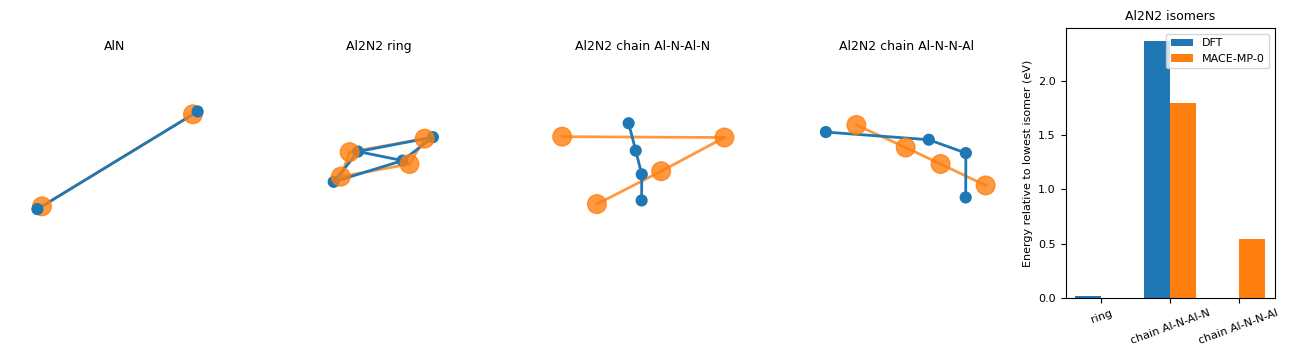

In [ ]:
fig = plt.figure(figsize=(13, 3.6))
for k, (name, (ad, am)) in enumerate(relaxed.items()):
    ax = fig.add_subplot(1, len(relaxed) + 1, k + 1, projection="3d")
    am_al = am.copy(); minimize_rotation_and_translation(ad, am_al)
    draw_molecule(ax, am_al, color="#ff7f0e", alpha=0.8, size=3.0)
    draw_molecule(ax, ad, color="#1f77b4", alpha=1.0, size=1.0)
    ax.set_title(name, fontsize=9)
ax = fig.add_subplot(1, len(relaxed) + 1, len(relaxed) + 1)
x = np.arange(len(iso)); w = 0.38
ax.bar(x - w / 2, iso.rel_dft_eV, w, label="DFT"); ax.bar(x + w / 2, iso.rel_mace_eV, w, label="MACE-MP-0")
ax.set_xticks(x); ax.set_xticklabels([c.replace("Al2N2 ", "") for c in iso.cluster], rotation=20, fontsize=8)
ax.set_ylabel("Energy relative to lowest isomer (eV)"); ax.legend(); ax.set_title("Al2N2 isomers", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_aln_clusters.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 16: The semiconductor itself, bulk AlN

AlN as a material is a crystal. At ambient pressure the stable form is the hexagonal **wurtzite** structure. Two other crystal structures, zincblende and rocksalt, are known or predicted. A basic stability question is: which of these has the lowest energy, and does the model predict the correct lattice constants?

MACE-MP-0 was trained mainly on crystal data, so this is the case it was built for. We relax the atoms and the cell for each structure and compare with literature lattice constants.
Periodic DFT with a plane-wave code (Quantum ESPRESSO, VASP) would be the reference, which is outside this notebook, so here the reference is the literature.

In [ ]:
def relax_crystal(atoms, calc, fmax=0.01, steps=400):
    a = atoms.copy(); a.calc = calc
    BFGS(FrechetCellFilter(a), logfile=None).run(fmax=fmax, steps=steps)
    return a

phases = {
    "wurtzite": bulk("AlN", "wurtzite", a=3.2, c=5.1),
    "zincblende": bulk("AlN", "zincblende", a=4.45),
    "rocksalt": bulk("AlN", "rocksalt", a=4.1),
}
brows, crystals = [], {}
for name, a0 in phases.items():
    t = time.perf_counter(); a = relax_crystal(a0, mp_calc); dt = time.perf_counter() - t
    crystals[name] = a
    cp = a.cell.cellpar()
    hexagonal = name == "wurtzite"
    brows.append(dict(phase=name, atoms=len(a), a_A=cp[0] if hexagonal else cp[0] * np.sqrt(2), c_A=cp[2] if hexagonal else np.nan,
                      volume_per_formula_A3=a.get_volume() / (len(a) / 2),
                      energy_per_atom_eV=a.get_potential_energy() / len(a), seconds=dt))
bulk_df = pd.DataFrame(brows)
bulk_df["rel_meV_per_atom"] = (bulk_df.energy_per_atom_eV - bulk_df.energy_per_atom_eV.min()) * 1000
print("a_A is the cubic lattice constant for zincblende and rocksalt, and the hexagonal a for wurtzite")
print(bulk_df.round(3).to_string(index=False))

w = bulk_df[bulk_df.phase == "wurtzite"].iloc[0]
zb = bulk_df[bulk_df.phase == "zincblende"].iloc[0]
print(f"wurtzite a: model {w.a_A:.3f} vs literature {LIT_A} A ({(w.a_A / LIT_A - 1) * 100:+.1f} %)")
print(f"wurtzite c: model {w.c_A:.3f} vs literature {LIT_C} A ({(w.c_A / LIT_C - 1) * 100:+.1f} %)")
print(f"wurtzite c/a: model {w.c_A / w.a_A:.3f}  literature {LIT_C / LIT_A:.3f}")
print(f"zincblende cubic lattice constant: model {zb.a_A:.3f} vs literature {LIT_A_ZB} A")
print("lowest-energy phase according to the model:", bulk_df.loc[bulk_df.energy_per_atom_eV.idxmin(), "phase"])

# Literature values for Wurtzute are 3.112 and 4.982 Angstrom for the two lattice constants

a_A is the cubic lattice constant for zincblende and rocksalt, and the hexagonal a for wurtzite
     phase  atoms   a_A   c_A  volume_per_formula_A3  energy_per_atom_eV  seconds  rel_meV_per_atom
  wurtzite      4 3.128 5.004                 21.199              -7.439    0.494             0.000
zincblende      2 4.395   NaN                 21.224              -7.422    0.169            17.097
  rocksalt      2 4.043   NaN                 16.522              -7.245    0.162           194.374
wurtzite a: model 3.128 vs literature 3.112 A (+0.5 %)
wurtzite c: model 5.004 vs literature 4.982 A (+0.5 %)
wurtzite c/a: model 1.600  literature 1.601
zincblende cubic lattice constant: model 4.395 vs literature 4.38 A
lowest-energy phase according to the model: wurtzite


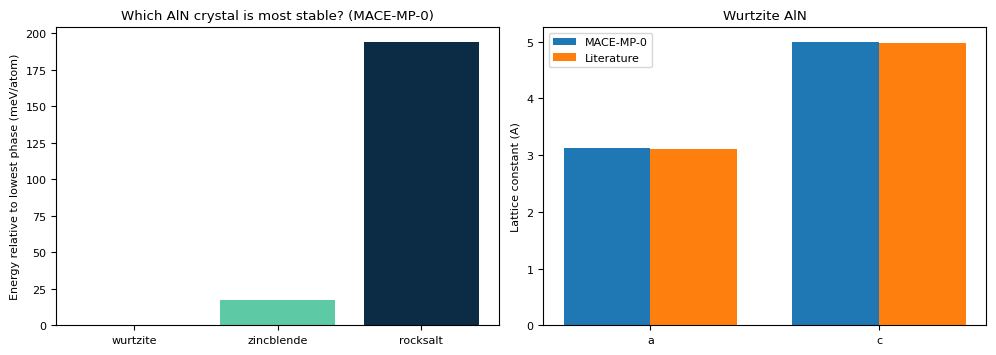

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(bulk_df.phase, bulk_df.rel_meV_per_atom, color=["#0F6E56", "#5DCAA5", "#0C2B45"])
ax[0].set_ylabel("Energy relative to lowest phase (meV/atom)"); ax[0].set_title("Which AlN crystal is most stable? (MACE-MP-0)")
lat = ["a", "c"]; mod = [w.a_A, w.c_A]; lit = [LIT_A, LIT_C]
x = np.arange(2); ax[1].bar(x - .19, mod, .38, label="MACE-MP-0"); ax[1].bar(x + .19, lit, .38, label="Literature")
ax[1].set_xticks(x); ax[1].set_xticklabels(["a", "c"]); ax[1].set_ylabel("Lattice constant (A)"); ax[1].legend(); ax[1].set_title("Wurtzite AlN")
plt.tight_layout(); plt.savefig(OUT_DIR / "dft_aln_bulk.png", dpi=150, bbox_inches="tight"); plt.show()
write(OUT_DIR / "dft_aln_wurtzite.cif", crystals["wurtzite"])

## Step 17: Part 2 summary

In [ ]:
part2 = {
    "cluster_dft_level": f"UKS {DFT_XC}/{DFT_BASIS}", "cluster_ai_model": f"MACE-MP-0 {MP_MODEL}",
    "spin_choice_2S": {k: int(v) for k, v in spin_choice.items()},
    "al2n2_order_dft": list(iso.sort_values("rel_dft_eV").cluster), "al2n2_order_mace": list(iso.sort_values("rel_mace_eV").cluster),
    "cluster_dft_total_s": round(float(spin_scan.seconds.sum()), 0), "cluster_mace_total_s": round(float(res.mace_s.sum()), 1),
    "wurtzite_a_model": round(float(w.a_A), 3), "wurtzite_c_model": round(float(w.c_A), 3), "wurtzite_a_lit": LIT_A, "wurtzite_c_lit": LIT_C,
    "stablest_bulk_phase_model": bulk_df.loc[bulk_df.energy_per_atom_eV.idxmin(), "phase"],
}
summary.update(part2)
json.dump(summary, open(OUT_DIR / "dft_summary.json", "w"), indent=2)
part2

{'cluster_dft_level': 'UKS b3lyp/def2-svp',
 'cluster_ai_model': 'MACE-MP-0 medium',
 'spin_choice_2S': {'AlN': 2,
  'Al2N2 ring': 0,
  'Al2N2 chain Al-N-Al-N': 2,
  'Al2N2 chain Al-N-N-Al': 2},
 'al2n2_order_dft': ['Al2N2 chain Al-N-N-Al',
  'Al2N2 ring',
  'Al2N2 chain Al-N-Al-N'],
 'al2n2_order_mace': ['Al2N2 ring',
  'Al2N2 chain Al-N-N-Al',
  'Al2N2 chain Al-N-Al-N'],
 'cluster_dft_total_s': 1271.0,
 'cluster_mace_total_s': 4.1,
 'wurtzite_a_model': 3.128,
 'wurtzite_c_model': 5.004,
 'wurtzite_a_lit': 3.112,
 'wurtzite_c_lit': 4.982,
 'stablest_bulk_phase_model': 'wurtzite'}

## A note on Skala (not run here)

The approach above replaces the electronic calculation. A different idea keeps DFT and improves its weakest ingredient, the exchange-correlation functional, which is traditionally a hand-designed approximation.
Microsoft's **Skala** is a deep-learning exchange-correlation functional trained on a large set of accurate reference energies, and it plugs into a normal self-consistent DFT calculation.
The accuracy numbers Microsoft reports have not been reproduced in this notebook, so treat them as the authors' claims. Integrations into mainstream DFT codes are in progress; check the project page for the current status and license before building on it.

## What this notebook did not do
- We used one small neutral closed-shell molecule near equilibrium. Bond breaking, radicals, charged species, metals and surfaces are harder for both approaches.
- MACE-OFF23 was trained at a different level of theory than our DFT. Differences include that mismatch.
- Part 2 uses a hybrid functional with a small basis, three spin states per cluster, one starting geometry per isomer, and no periodic DFT. Close spin states and isomers can change order with a different functional, basis or starting structure, and we tried only a few isomers.
- MACE-MP-0 has no notion of spin and was trained mostly on crystals, so the cluster results test it outside its main domain.
- Other universal models exist (for example MACE-MP-0 for materials with 89 elements, and Meta's UMA family), each with its own training data, coverage and license.